In [87]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [88]:
df=pd.read_csv('Dataset.csv')

In [89]:
df['sales'] = pd.to_numeric(df['sales'].astype(str).str.replace(',', ''), errors='coerce')
df['profit'] = pd.to_numeric(df['profit'], errors='coerce')
df.fillna(0, inplace=True)

In [92]:
df['is_profitable'] = np.where(df['profit'] > 0, 1, 0)

cat_cols = ['ship_mode', 'segment', 'market', 'region', 'category', 'sub_category', 'order_priority']
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

X_class = df.drop(columns=['order_id', 'order_date', 'ship_date', 'customer_name', 'state', 'country', 'product_id', 'product_name', 'profit', 'is_profitable'])
y_class = df['is_profitable']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, random_state=42)
}

clf_results = []
for name, model in clf_models.items():
    model.fit(Xc_train, yc_train)
    preds = model.predict(Xc_test)
    acc = accuracy_score(yc_test, preds)
    f1 = f1_score(yc_test, preds)
    clf_results.append({'Model': name, 'Accuracy': acc, 'F1-Score': f1})
    print(f"[Classification] {name} -> Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")

clf_df = pd.DataFrame(clf_results)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[Classification] Logistic Regression -> Accuracy: 0.9247 | F1-Score: 0.9509
[Classification] Decision Tree -> Accuracy: 0.8876 | F1-Score: 0.9244
[Classification] Random Forest -> Accuracy: 0.9226 | F1-Score: 0.9491


In [93]:
X_reg = df[['sales', 'quantity', 'discount', 'category', 'region', 'segment']]
y_reg = df['profit']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=50, random_state=42)
}

reg_results = []
for name, model in reg_models.items():
    model.fit(Xr_train, yr_train)
    preds = model.predict(Xr_test)
    rmse = np.sqrt(mean_squared_error(yr_test, preds))
    r2 = r2_score(yr_test, preds)
    reg_results.append({'Model': name, 'RMSE': rmse, 'R2-Score': r2})
    print(f"[Regression] {name} -> RMSE: {rmse:.4f} | R² Score: {r2:.4f}")

reg_df = pd.DataFrame(reg_results)

[Regression] Linear Regression -> RMSE: 127.4523 | R² Score: 0.3874
[Regression] Decision Tree Regressor -> RMSE: 117.6308 | R² Score: 0.4782
[Regression] Random Forest Regressor -> RMSE: 88.1160 | R² Score: 0.7072


/tmp/ipykernel_421/3671667399.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='crest')


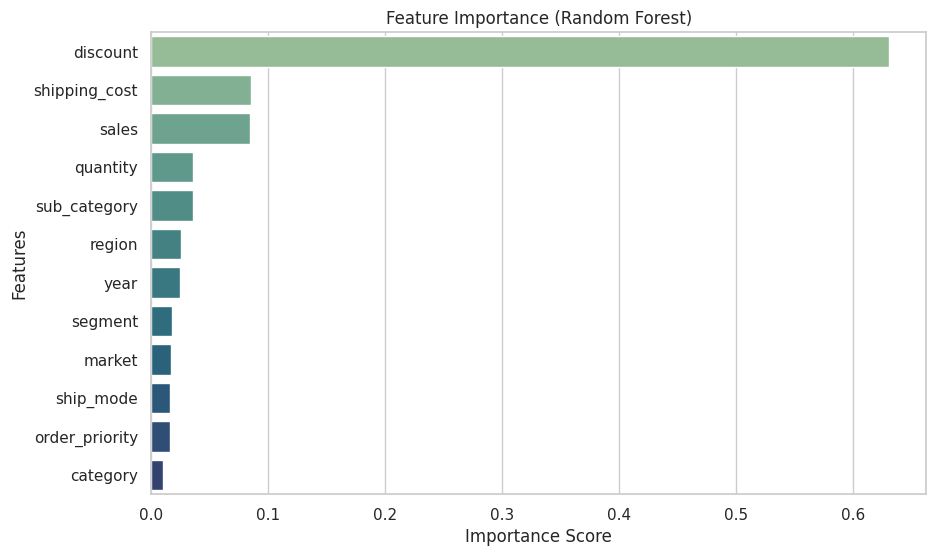

In [94]:
rf_model = RandomForestClassifier(n_estimators=50, random_state=42)
rf_model.fit(Xc_train, yc_train)

feature_importance = pd.DataFrame({
    'Feature': X_class.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='crest')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

###  Key Findings & Summary

* **Data Preparation & Preprocessing (Level 1):** Successfully cleaned the raw dataset by handling missing values and outliers.
* **Exploratory Data Analysis (EDA) (Level 1):** Uncovered key business insights through visualisations.
* **Machine Learning (Level 2 & 3):** Developed and compared classification and regression models successfully.

